<a href="https://colab.research.google.com/github/vragarwal/FDS-Results/blob/main/vradhi%20exp%208%20fds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print(df.head())
print(df.shape)

Saving V_S_DATA SET_CLIMATE.csv to V_S_DATA SET_CLIMATE.csv
       country  longitude        timezone      last_updated  \
0  Afghanistan      69.18      Asia/Kabul  16-05-2024 13:15   
1      Albania      19.82   Europe/Tirane  16-05-2024 10:45   
2      Algeria       3.05  Africa/Algiers  16-05-2024 09:45   
3      Andorra       1.52  Europe/Andorra  16-05-2024 10:45   
4       Angola      13.23   Africa/Luanda  16-05-2024 09:45   

   temperature_celsius condition_text  wind_kph  wind_degree wind_direction  \
0                 26.6  Partly Cloudy      13.3          338            NNW   
1                 19.0  Partly cloudy      11.2          320             NW   
2                 23.0          Sunny      15.1          280              W   
3                  6.3  Light drizzle      11.9          215             SW   
4                 26.0  Partly cloudy      13.0          150            SSE   

   precip_mm  humidity  visibility_km  gust_mph  air_quality_Ozone  \
0        0.0    

In [ ]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155336 entries, 0 to 155335
Data columns (total 18 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   country                   155336 non-null  object 
 1   longitude                 155336 non-null  float64
 2   timezone                  155336 non-null  object 
 3   last_updated              155336 non-null  object 
 4   temperature_celsius       155336 non-null  float64
 5   condition_text            155336 non-null  object 
 6   wind_kph                  155336 non-null  float64
 7   wind_degree               155336 non-null  int64  
 8   wind_direction            155336 non-null  object 
 9   precip_mm                 155336 non-null  float64
 10  humidity                  155336 non-null  int64  
 11  visibility_km             155336 non-null  float64
 12  gust_mph                  155336 non-null  float64
 13  air_quality_Ozone      

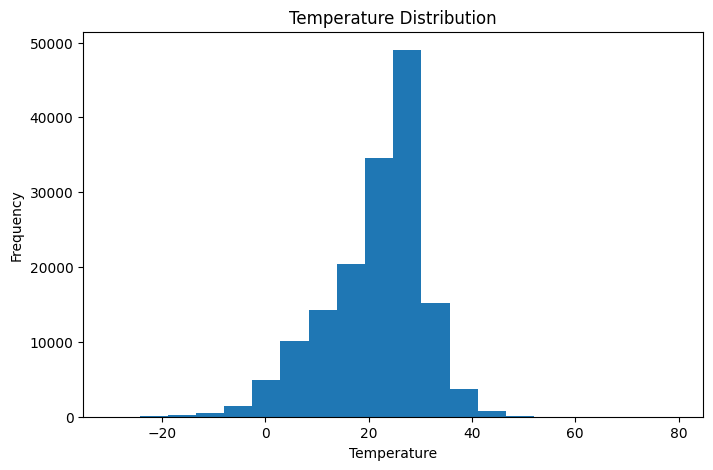

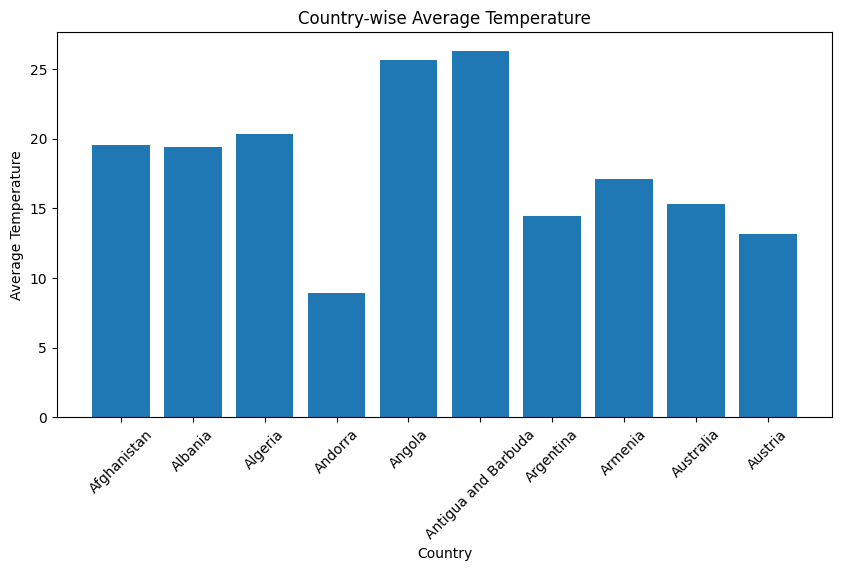

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['temperature_celsius'].dropna(), bins=20)
plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.show()

country_temp = df.groupby('country')['temperature_celsius'].mean().head(10)

plt.figure(figsize=(10,5))
plt.bar(country_temp.index, country_temp.values)
plt.title("Country-wise Average Temperature")
plt.xlabel("Country")
plt.ylabel("Average Temperature")
plt.xticks(rotation=45)
plt.show()

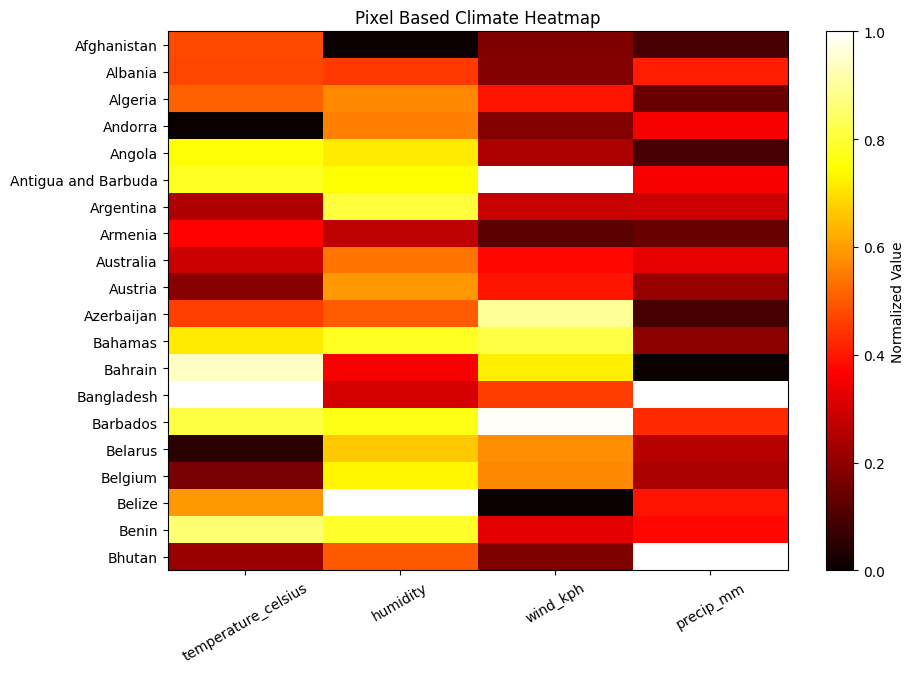

In [ ]:
data = df.groupby('country')[
    ['temperature_celsius', 'humidity', 'wind_kph', 'precip_mm']
].mean().head(20)

data = (data - data.min()) / (data.max() - data.min())

plt.figure(figsize=(10,7))
plt.imshow(data, cmap='hot', aspect='auto')
plt.colorbar(label="Normalized Value")
plt.xticks(range(len(data.columns)), data.columns, rotation=30)
plt.yticks(range(len(data.index)), data.index)
plt.title("Pixel Based Climate Heatmap")
plt.show()

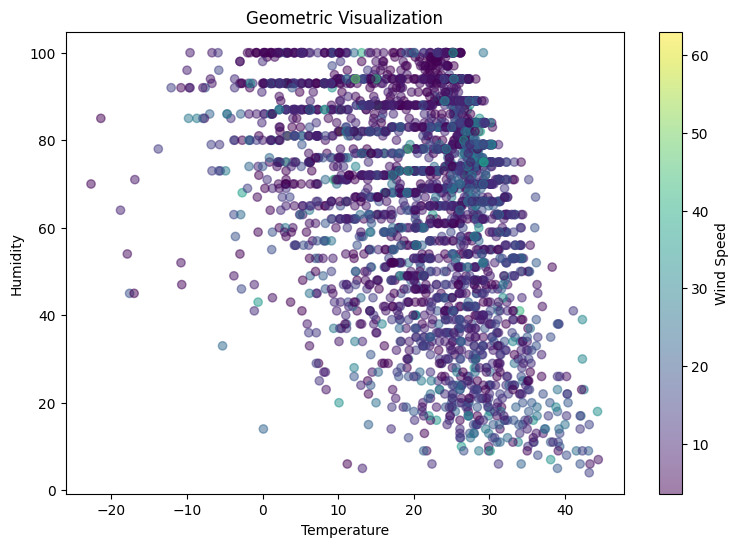

In [ ]:
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(9,6))
plt.scatter(
    sample['temperature_celsius'],
    sample['humidity'],
    c=sample['wind_kph'],
    cmap='viridis',
    alpha=0.5
)

plt.colorbar(label="Wind Speed")
plt.title("Geometric Visualization")
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.show()

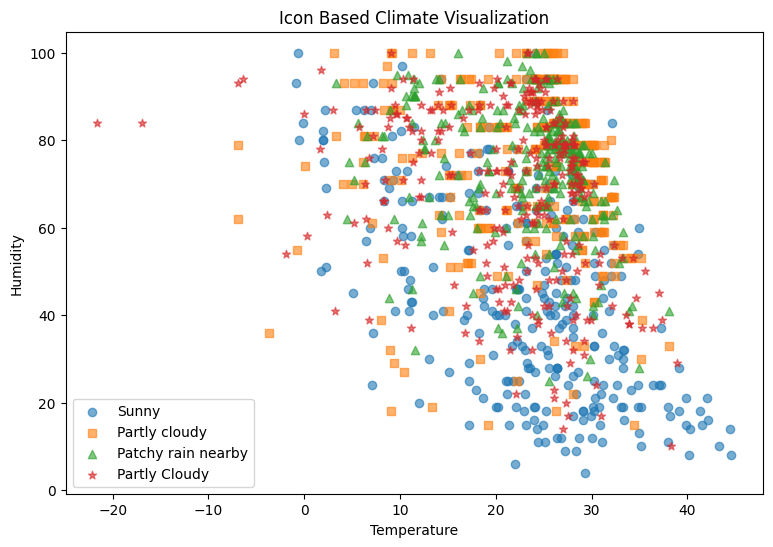

In [ ]:
conditions = df['condition_text'].value_counts().head(4).index

markers = ['o', 's', '^', '*']

plt.figure(figsize=(9,6))

for i in range(len(conditions)):
    data = df[df['condition_text'] == conditions[i]].sample(
        min(300, len(df[df['condition_text'] == conditions[i]])),
        random_state=42
    )

    plt.scatter(
        data['temperature_celsius'],
        data['humidity'],
        marker=markers[i],
        label=conditions[i],
        alpha=0.6
    )

plt.title("Icon Based Climate Visualization")
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.legend()
plt.show()

In [ ]:
import plotly.express as px

top = df['country'].value_counts().head(10).index

hierarchy = df[df['country'].isin(top)]

hierarchy = hierarchy.groupby(
    ['country', 'condition_text']
).size().reset_index(name='count')

fig = px.treemap(
    hierarchy,
    path=['country', 'condition_text'],
    values='count',
    title="Hierarchy Based Climate Visualization"
)

fig.show()

In [ ]:
import plotly.express as px

country_data = df.groupby('country')['temperature_celsius'].mean().reset_index()

fig = px.bar(
    country_data.head(15),
    x='country',
    y='temperature_celsius',
    title='Interactive Country-wise Temperature Analysis',
    labels={
        'country': 'Country',
        'temperature_celsius': 'Average Temperature'
    }
)

fig.show()